# Heart Disease Analysis and Model Comparison
Exploratory data analysis of a heart disease dataset, followed by a comparison of four classifiers: Logistic Regression, KNN, Naive Bayes and Random Forest.

**Note:** keep `heart_dataset.csv` in the same folder as this notebook.

## 1. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import plot_tree

## 2. Load Dataset

In [2]:
df = pd.read_csv("heart_dataset.csv")

print("First five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

First five rows:
   age  sex  chest pain type  ...  oldpeak  ST slope  target
0   40    1                2  ...      0.0         1       0
1   49    0                3  ...      1.0         2       1
2   37    1                2  ...      0.0         1       0
3   48    0                4  ...      1.5         2       1
4   54    1                3  ...      0.0         1       0

[5 rows x 12 columns]

Last five rows:
      age  sex  chest pain type  ...  oldpeak  ST slope  target
1185   45    1                1  ...      1.2         2       1
1186   68    1                4  ...      3.4         2       1
1187   57    1                4  ...      1.2         2       1
1188   57    0                2  ...      0.0         2       1
1189   38    1                3  ...      0.0         1       0

[5 rows x 12 columns]

Dataset shape:
(1190, 12)


In [3]:
print("Dataset information:")
print(df.info())

print("\nDataset description:")
print(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1190 entries, 0 to 1189
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1190 non-null   int64  
 1   sex                  1190 non-null   int64  
 2   chest pain type      1190 non-null   int64  
 3   resting bp s         1190 non-null   int64  
 4   cholesterol          1190 non-null   int64  
 5   fasting blood sugar  1190 non-null   int64  
 6   resting ecg          1190 non-null   int64  
 7   max heart rate       1190 non-null   int64  
 8   exercise angina      1190 non-null   int64  
 9   oldpeak              1190 non-null   float64
 10  ST slope             1190 non-null   int64  
 11  target               1190 non-null   int64  
dtypes: float64(1), int64(11)
memory usage: 111.7 KB
None

Dataset description:
               age          sex  ...     ST slope       target
count  1190.000000  1190.000000  ...  11

In [4]:
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Data types:
age                      int64
sex                      int64
chest pain type          int64
resting bp s             int64
cholesterol              int64
fasting blood sugar      int64
resting ecg              int64
max heart rate           int64
exercise angina          int64
oldpeak                float64
ST slope                 int64
target                   int64
dtype: object

Missing values:
age                    0
sex                    0
chest pain type        0
resting bp s           0
cholesterol            0
fasting blood sugar    0
resting ecg            0
max heart rate         0
exercise angina        0
oldpeak                0
ST slope               0
target                 0
dtype: int64

Duplicate rows:
272


## Objective 1: Heart Disease Distribution

Heart Disease Distribution:
target
1    629
0    561
Name: count, dtype: int64


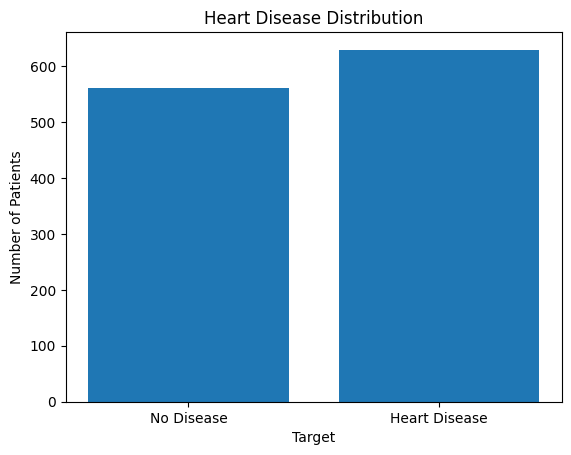

In [5]:
print("Heart Disease Distribution:")

target_count = df["target"].value_counts()

print(target_count)

plt.figure()

plt.bar(
    ["No Disease", "Heart Disease"],
    [target_count.loc[0], target_count.loc[1]]
)

plt.title("Heart Disease Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Patients")

plt.show()

## Objective 2: Age and Sex

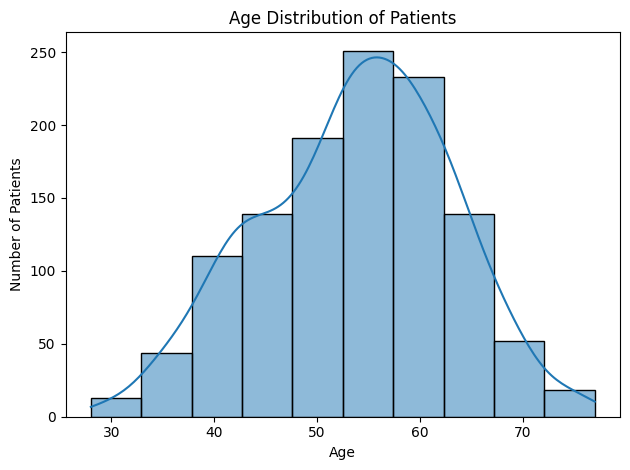

In [6]:
# Age distribution
sns.histplot(df["age"], bins=10, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

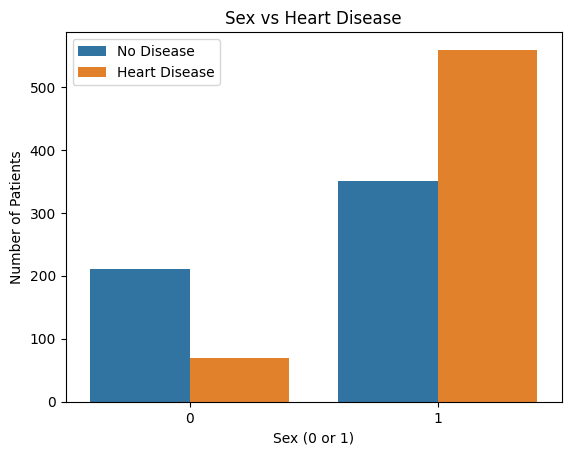

In [7]:
# Sex compared with heart disease status
plt.figure()

sns.countplot(x="sex", hue="target", data=df)

plt.title("Sex vs Heart Disease")
plt.xlabel("Sex (0 or 1)")
plt.ylabel("Number of Patients")
plt.legend(["No Disease", "Heart Disease"])

plt.show()

## Objective 3: Chest Pain Type Distribution

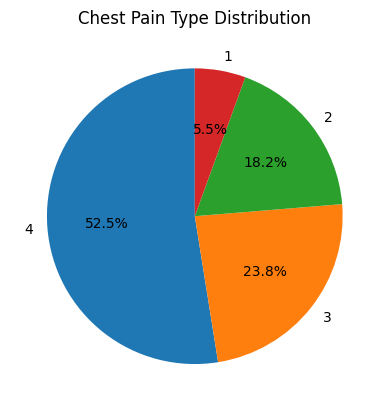

In [8]:
chest_pain = df["chest pain type"].value_counts()

plt.figure()

plt.pie(
    chest_pain.values,
    labels=chest_pain.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Chest Pain Type Distribution")

plt.show()

## Objective 4: Cholesterol Levels Across Age Groups

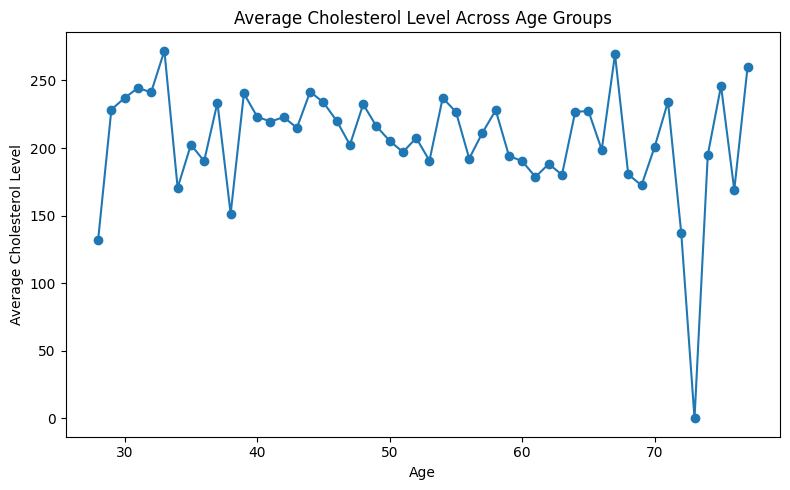

In [9]:
age_cholesterol = df.groupby("age")["cholesterol"].mean()

plt.figure(figsize=(8, 5))

plt.plot(age_cholesterol.index, age_cholesterol.values, marker="o")

plt.title("Average Cholesterol Level Across Age Groups")
plt.xlabel("Age")
plt.ylabel("Average Cholesterol Level")

plt.tight_layout()
plt.show()

## Objective 5: Correlation Analysis

Correlation Matrix:
                          age       sex  ...  ST slope    target
age                  1.000000  0.015096  ...  0.237749  0.262029
sex                  0.015096  1.000000  ...  0.127913  0.311267
chest pain type      0.149055  0.138405  ...  0.276949  0.460127
resting bp s         0.257692 -0.006443  ...  0.089384  0.121415
cholesterol         -0.046472 -0.208441  ... -0.100053 -0.198366
fasting blood sugar  0.178923  0.110961  ...  0.145902  0.216695
resting ecg          0.194595 -0.022225  ...  0.093629  0.073059
max heart rate      -0.368676 -0.181837  ... -0.350750 -0.413278
exercise angina      0.188095  0.194380  ...  0.393408  0.481467
oldpeak              0.245093  0.096390  ...  0.524639  0.398385
ST slope             0.237749  0.127913  ...  1.000000  0.505608
target               0.262029  0.311267  ...  0.505608  1.000000

[12 rows x 12 columns]


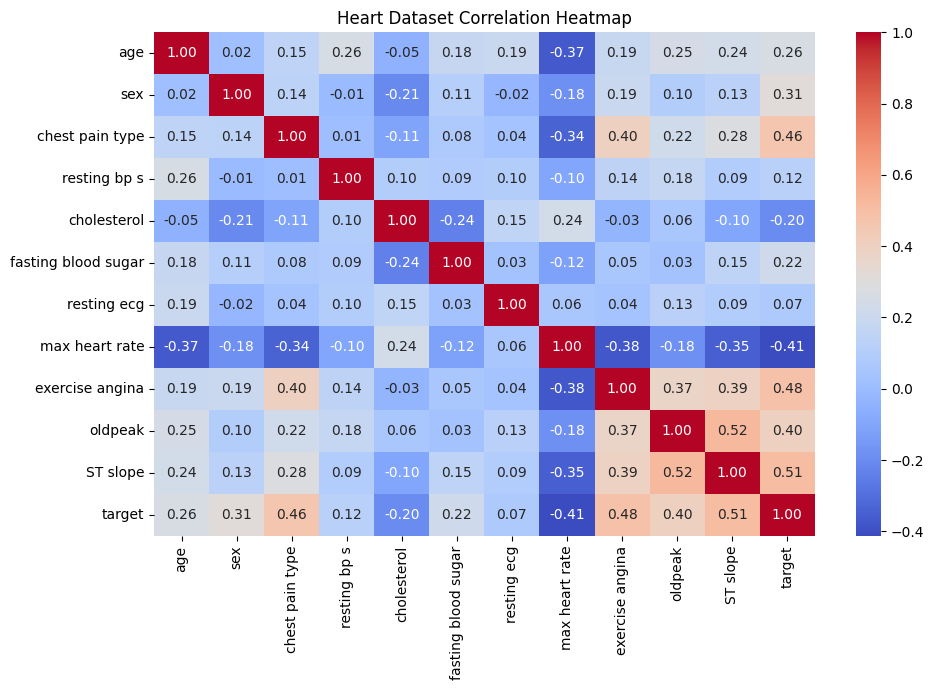

In [10]:
corr = df.corr()

print("Correlation Matrix:")
print(corr)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heart Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

## Prepare Data for Machine Learning

In [11]:
# Features and target
X = df.drop("target", axis=1)
y = df["target"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Standard scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (952, 11)
Test shape: (238, 11)


## Model 1: Logistic Regression

In [12]:
model1 = LogisticRegression(max_iter=1000)

model1.fit(X_train, y_train)

y_pred1 = model1.predict(X_test)

print("LOGISTIC REGRESSION")

print("Accuracy:", accuracy_score(y_test, y_pred1))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred1))

print("Classification Report:")
print(classification_report(y_test, y_pred1))

LOGISTIC REGRESSION
Accuracy: 0.8613445378151261
Confusion Matrix:
[[ 90  17]
 [ 16 115]]
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.84      0.85       107
           1       0.87      0.88      0.87       131

    accuracy                           0.86       238
   macro avg       0.86      0.86      0.86       238
weighted avg       0.86      0.86      0.86       238



## Model 2: K-Nearest Neighbors (KNN)

In [13]:
model2 = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

model2.fit(X_train, y_train)

y_pred2 = model2.predict(X_test)

print("K-NEAREST NEIGHBORS")

print("Accuracy:", accuracy_score(y_test, y_pred2))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred2))

print("Classification Report:")
print(classification_report(y_test, y_pred2))

K-NEAREST NEIGHBORS
Accuracy: 0.8865546218487395
Confusion Matrix:
[[ 89  18]
 [  9 122]]
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.83      0.87       107
           1       0.87      0.93      0.90       131

    accuracy                           0.89       238
   macro avg       0.89      0.88      0.88       238
weighted avg       0.89      0.89      0.89       238



## Model 3: Naive Bayes

In [14]:
model3 = GaussianNB()

model3.fit(X_train, y_train)

y_pred3 = model3.predict(X_test)

print("NAIVE BAYES")

print("Accuracy:", accuracy_score(y_test, y_pred3))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred3))

print("Classification Report:")
print(classification_report(y_test, y_pred3))

NAIVE BAYES
Accuracy: 0.8571428571428571
Confusion Matrix:
[[ 89  18]
 [ 16 115]]
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.83      0.84       107
           1       0.86      0.88      0.87       131

    accuracy                           0.86       238
   macro avg       0.86      0.85      0.86       238
weighted avg       0.86      0.86      0.86       238



## Model 4: Random Forest

In [15]:
model4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model4.fit(X_train, y_train)

y_pred4 = model4.predict(X_test)

print("RANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, y_pred4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred4))

print("Classification Report:")
print(classification_report(y_test, y_pred4))

RANDOM FOREST
Accuracy: 0.9453781512605042
Confusion Matrix:
[[ 98   9]
 [  4 127]]
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       107
           1       0.93      0.97      0.95       131

    accuracy                           0.95       238
   macro avg       0.95      0.94      0.94       238
weighted avg       0.95      0.95      0.95       238



### Random Forest: Decision Tree Visualization

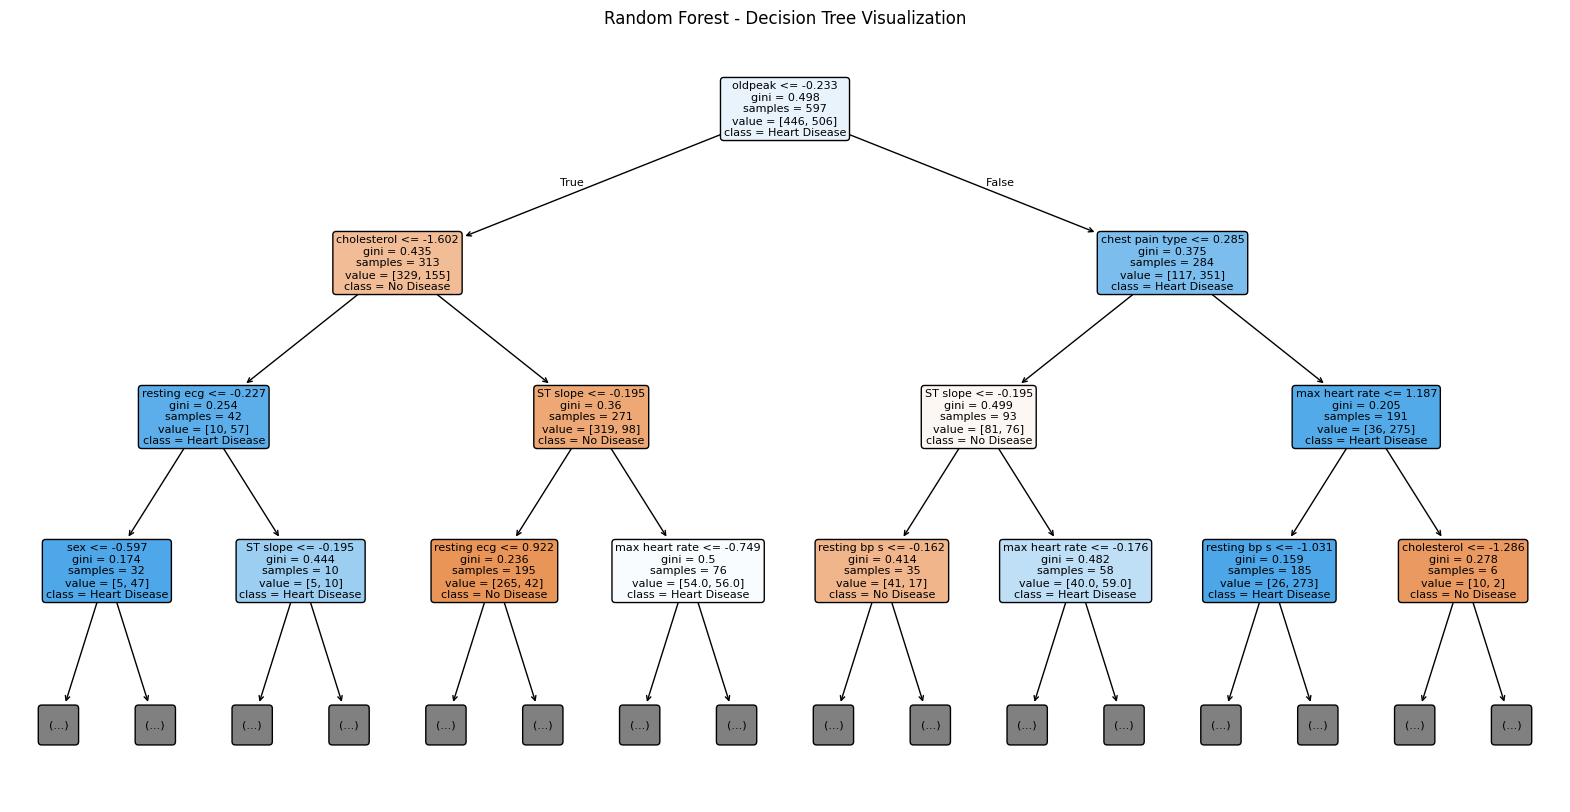

In [16]:
# Visualize one decision tree from Random Forest
plt.figure(figsize=(20, 10))

plot_tree(
    model4.estimators_[0],
    feature_names=X.columns,
    class_names=["No Disease", "Heart Disease"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Random Forest - Decision Tree Visualization")
plt.show()

### Random Forest: Feature Importance

Random Forest Feature Importance:
                Feature  Importance
10             ST slope    0.194539
2       chest pain type    0.134759
9               oldpeak    0.116515
7        max heart rate    0.116115
4           cholesterol    0.111434
0                   age    0.094971
3          resting bp s    0.078512
8       exercise angina    0.068288
1                   sex    0.038240
6           resting ecg    0.027517
5   fasting blood sugar    0.019110


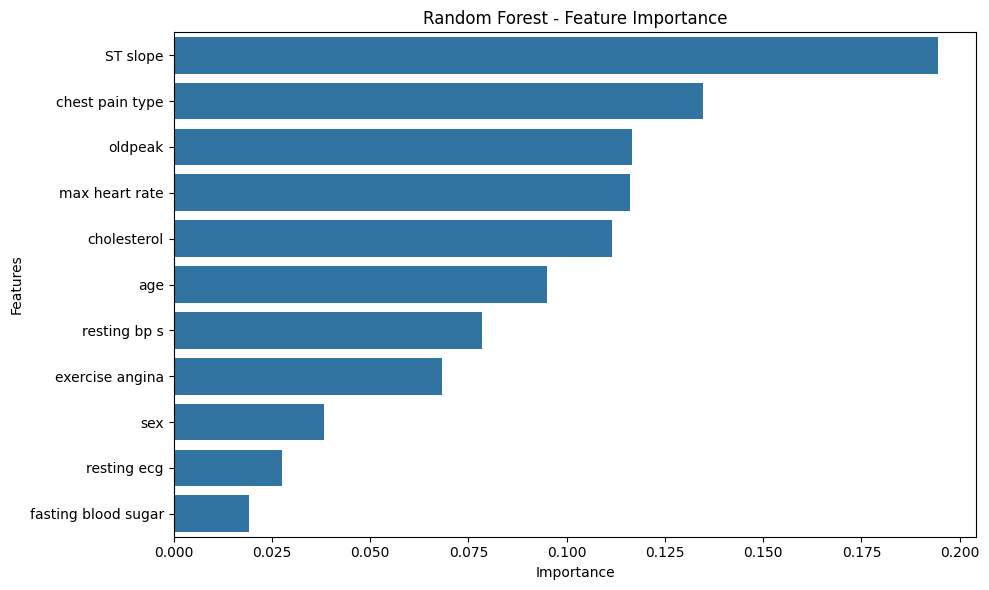

In [17]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model4.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## Compare All Four Models

In [18]:
results = {
    "Logistic Regression": accuracy_score(y_test, y_pred1),
    "KNN": accuracy_score(y_test, y_pred2),
    "Naive Bayes": accuracy_score(y_test, y_pred3),
    "Random Forest": accuracy_score(y_test, y_pred4)
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

print("MODEL ACCURACY COMPARISON:")
print(results_df)

# Find the model with the highest accuracy
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("\nBest Model:")
print(best_model["Model"])

print(
    "Best Accuracy:",
    round(best_model["Accuracy"] * 100, 2),
    "%"
)

MODEL ACCURACY COMPARISON:
                 Model  Accuracy
0  Logistic Regression  0.861345
1                  KNN  0.886555
2          Naive Bayes  0.857143
3        Random Forest  0.945378

Best Model:
Random Forest
Best Accuracy: 94.54 %


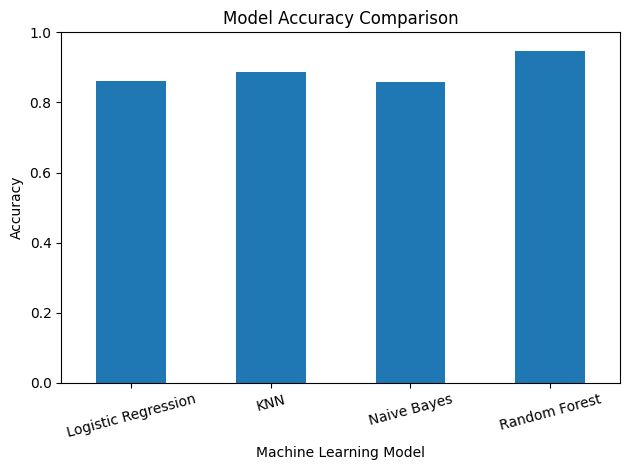

In [19]:
# Plot model comparison
results_df.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()